# LLH scans of the binary dials
Post-fit 1D scans (all other parameters fixed at post-fit). Input files come from `config_Fitter_*_Scan.yaml`.

In [1]:
import numpy as np, uproot
import matplotlib.pyplot as plt

BASE = ("/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/"
        "\U0001f3db PhD Repository/\U0001f680 Research/\U0001f916 Experiments&Projects/ICARUS/"
        "ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/")
# post-fit scan files (config_Fitter_*_Scan.yaml); add more studies here to compare
FILES = {
    "QE x0.8 fake data": BASE + "FakeData_InteractionMode_QE_Containment/scan_fakeData_InteractionMode_QE_dpT_containment.root",
    "Real data":         BASE + "RealData/real_dpT.root",
}
DIALS = [(48, "VecFFCCQEshape"), (49, "DecayAngMEC"), (50, "Theta_Delta2Npi"), (51, "ThetaDelta2NRad")]
G = "FitterEngine/postFit/scan/{kind}/Cross_section_Systematics_{i}_GENIEReWeight_SBN_v1_multisigma_{n}_TGraph"
FIT_WINDOW = 0.4   # sigma, half-width of the parabola fit around the minimum

def rd(f, kind, i, n):
    m = f[G.format(kind=kind, i=i, n=n)].all_members
    return np.asarray(m["fX"], float), np.asarray(m["fY"], float)

QE x0.8 fake data: post-fit scans
dial                 min at  fit sigma  dLLH(-3)  dLLH(+3)
VecFFCCQEshape        -0.00       0.57     12.45     12.45
DecayAngMEC            0.00       0.07    322.64    322.64
Theta_Delta2Npi       -0.00       0.26     26.94     26.94
ThetaDelta2NRad       -0.00       1.00      9.00      9.00


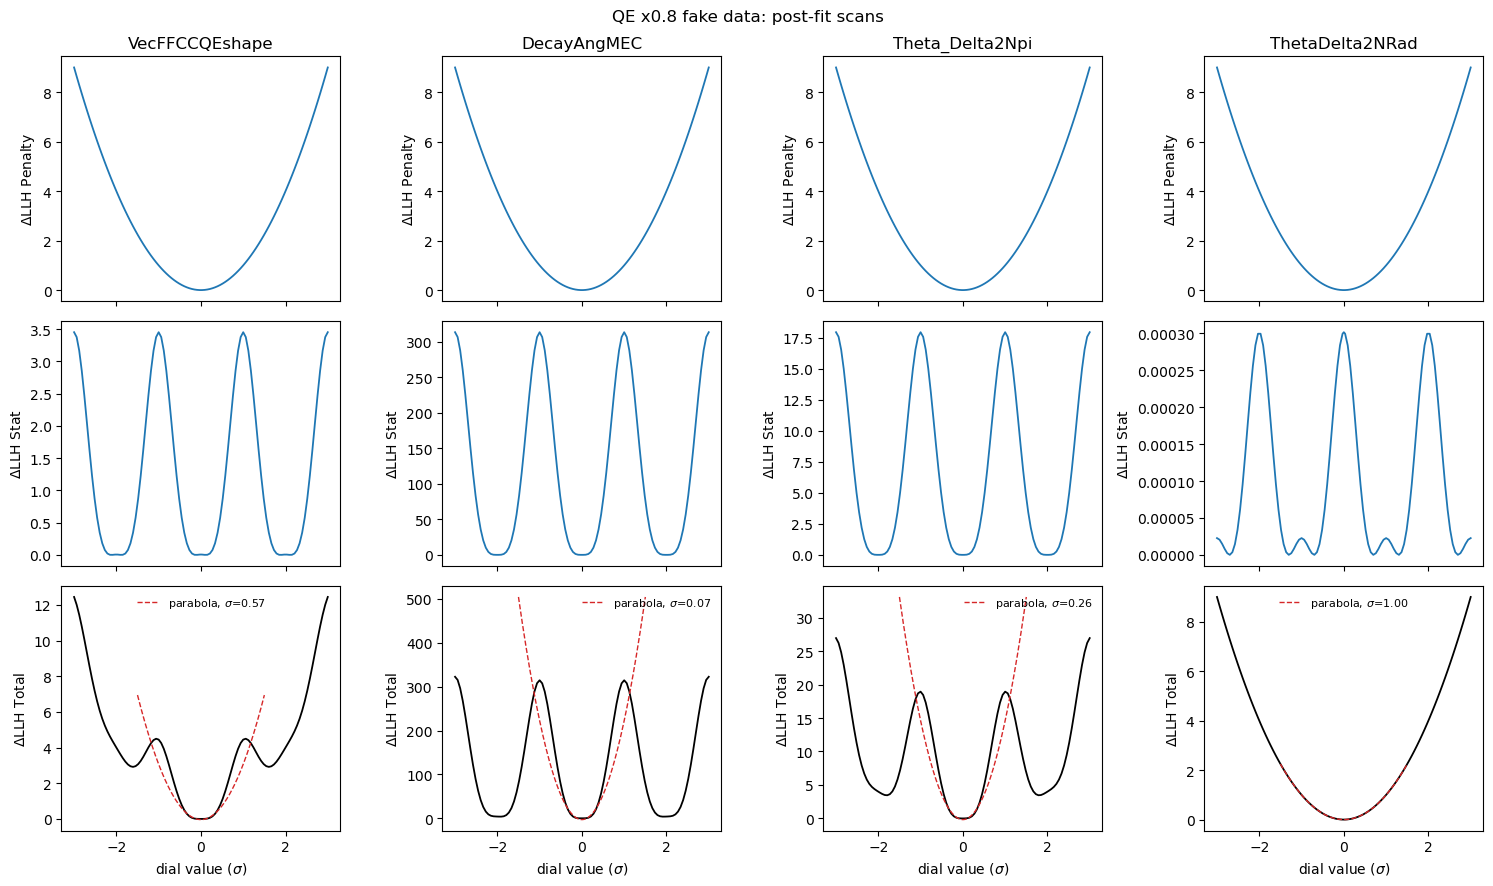

In [2]:
def scan_figure(path, title):
    """Penalty / Stat / Total Delta LLH for each binary dial, parabola fit on the Total."""
    with uproot.open(path) as f:
        fig, axs = plt.subplots(3, 4, figsize=(15, 9), sharex="col")
        print(title)
        print(f"{'dial':18s} {'min at':>8s} {'fit sigma':>10s} {'dLLH(-3)':>9s} {'dLLH(+3)':>9s}")
        for c, (i, n) in enumerate(DIALS):
            for r, (kind, lab) in enumerate((("llhPenalty", "Penalty"), ("llhStat", "Stat"), ("llh", "Total"))):
                x, y = rd(f, kind, i, n); y = y - y.min()
                axs[r, c].plot(x, y, "k-" if kind == "llh" else "-", lw=1.3)
                axs[r, c].set_ylabel(rf"$\Delta$LLH {lab}")
                if kind == "llh":
                    x0 = x[np.argmin(y)]; sel = np.abs(x - x0) <= FIT_WINDOW
                    B = np.polyfit(x[sel], y[sel], 2); A = B[0]
                    sg = 1/np.sqrt(A) if A > 0 else np.inf      # same convention as the RealData study
                    xx = np.linspace(x0 - 1.5, x0 + 1.5, 200)
                    axs[r, c].plot(xx, np.polyval(B, xx), "C3--", lw=1, label=rf"parabola, $\sigma$={sg:.2f}")
                    axs[r, c].legend(frameon=False, fontsize=8)
                    print(f"{n:18s} {x0:8.2f} {sg:10.2f} {y[0]:9.2f} {y[-1]:9.2f}")
            axs[0, c].set_title(n); axs[2, c].set_xlabel(r"dial value ($\sigma$)")
        fig.suptitle(title); fig.tight_layout(); plt.show()

scan_figure(FILES["QE x0.8 fake data"], "QE x0.8 fake data: post-fit scans")

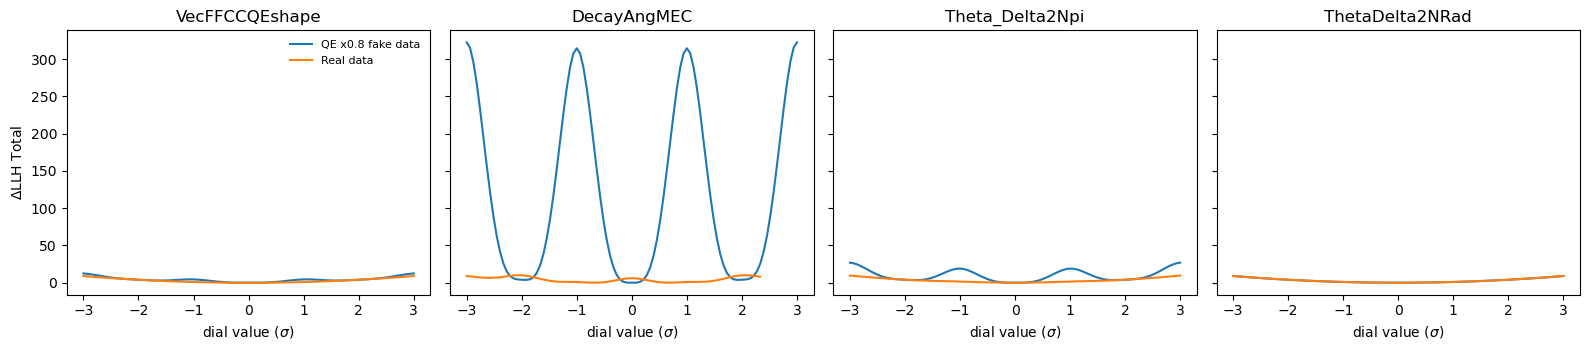

In [3]:
# Total Delta LLH, fake data vs real data on the same axes
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for lab, p in FILES.items():
    with uproot.open(p) as f:
        for ax, (i, n) in zip(axs, DIALS):
            x, y = rd(f, "llh", i, n); ax.plot(x, y - y.min(), label=lab); ax.set_title(n)
for ax in axs: ax.set_xlabel(r"dial value ($\sigma$)")
axs[0].set_ylabel(r"$\Delta$LLH Total"); axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Curvature at the minimum from the scan: sigma_eff(h) = 1/sqrt(A), A = [L(h)+L(-h)-2L(0)]/(2h^2)
# compare with the Hesse sigma of the nominal fit. Use the FINE scan file for h below the coarse grid step (0.06).
FIT = FILES["QE x0.8 fake data"]            # swap for the fine-scan file once available
HESSE = {"VecFFCCQEshape": 3.18, "DecayAngMEC": 0.58, "Theta_Delta2Npi": 0.80, "ThetaDelta2NRad": 1.00}
hs = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0])
fig, ax = plt.subplots(figsize=(7, 4))
with uproot.open(FIT) as f:
    for i, n in DIALS:
        x, y = rd(f, "llh", i, n); L = lambda t: np.interp(t, x, y)
        hh = hs[(hs >= np.diff(x).max()) & (hs <= x.max())]
        A = (L(hh) + L(-hh) - 2*L(0)) / (2*hh**2)
        ax.plot(hh, np.where(A > 0, 1/np.sqrt(np.abs(A)), np.nan), "o-", label=n)
        ax.axhline(HESSE[n], ls=":", color=ax.lines[-1].get_color())
ax.set_xscale("log"); ax.set_xlabel("finite-difference step h (sigma)"); ax.set_ylabel("effective sigma (dotted: Hesse)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()